# Program 8: Apply Feature Engineering Techniques Including Feature Selection and
Dimensionality Reduction Using Principal Component Analysis (PCA)

**1. Aim**
To apply feature engineering techniques, including feature selection and dimensionality
reduction using Principal Component Analysis (PCA), to improve the quality of data and
prepare it for machine learning models.

**2. Objectives**

After completing this experiment, students will be able to:
• Understand the concept of feature engineering.
• Learn the importance of feature selection.
• Identify relevant features from a dataset.
• Apply dimensionality reduction using Principal Component Analysis (PCA).
• Reduce computational complexity while preserving important information.
• Visualize transformed features.
• Prepare optimized datasets for machine learning.

**3. Theory**
3.1 Introduction to Feature Engineering
Feature Engineering is the process of selecting, creating, transforming, and improving features
(input variables) to enhance the performance of machine learning models.
A feature is an individual measurable property or characteristic of the data.
Example:
Suppose a student dataset contains:
Name Age Attendance Marks
John 20 90 85
Features are:
• Age
• Attendance
Target Variable:
• Marks

Feature engineering transforms raw data into meaningful information that improves predictive
performance.

3.2 Importance of Feature Engineering
Feature engineering helps to:
• Improve prediction accuracy.
• Reduce unnecessary data.
• Minimize overfitting.
• Reduce training time.
• Improve model interpretability.
• Handle high-dimensional datasets efficiently.

3.3 Types of Feature Engineering
1. Feature Selection
Selecting only the most relevant features from the dataset.
Example:
Original Features
Age
Salary
Department
Employee ID
Attendance
Selected Features
Age
Salary
Attendance
Employee ID may be removed because it does not contribute to prediction.

2. Feature Extraction
Combining existing features to create new informative features.
Example:
Height

Weight
New Feature:
Body Mass Index (BMI)

3. Feature Transformation
Changing the representation of data.
Examples:
• Normalization
• Standardization
• Log Transformation
• Encoding Categorical Variables

3.4 Feature Selection
Feature Selection is the process of choosing the most important input variables while removing
irrelevant or redundant features.
Benefits
• Faster model training.
• Reduced memory usage.
• Improved model accuracy.
• Reduced overfitting.
• Easier interpretation.

Types of Feature Selection
A. Filter Methods
Features are selected based on statistical tests.
Examples:
• Correlation
• Chi-Square Test
• ANOVA
• Mutual Information

B. Wrapper Methods
Feature subsets are evaluated using a machine learning model.
Examples:
• Forward Selection
• Backward Elimination
• Recursive Feature Elimination (RFE)

C. Embedded Methods
Feature selection occurs during model training.
Examples:
• Lasso Regression
• Decision Trees
• Random Forest

3.5 What is Dimensionality Reduction?
Dimensionality Reduction is the process of reducing the number of input variables while
preserving the important information contained in the dataset.
Instead of using 100 features, a reduced set of informative features is created.
Benefits include:
• Faster computation.
• Reduced storage requirements.
• Improved visualization.
• Reduced noise.
• Lower risk of overfitting.

3.6 Principal Component Analysis (PCA)
Principal Component Analysis (PCA) is an unsupervised dimensionality reduction
technique that transforms a large set of correlated features into a smaller set of uncorrelated
variables called Principal Components.
These principal components retain most of the variation (information) present in the original
data.

3.7 Working of PCA
PCA follows these steps:
1. Standardize the dataset.
2. Compute the covariance matrix.
3. Calculate eigenvalues and eigenvectors.
4. Sort principal components based on explained variance.
5. Select the top principal components.
6. Transform the original data into the reduced feature space.

3.8 Why Standardization is Required Before PCA
Features often have different scales.
Example:
Feature Value
Age 25
Salary 500000
Without standardization, Salary would dominate the principal components.
Using StandardScaler, all features are transformed to have:
• Mean = 0
• Standard Deviation = 1
This ensures each feature contributes equally to PCA.

3.9 Explained Variance
Each principal component explains a portion of the total variance in the dataset.
Example:
Principal Component Explained Variance
PC1 72%
PC2 18%
PC3 6%
PC4 4%
Here, the first two components explain 90% of the information, so the remaining components
can often be discarded.

3.10 Applications of PCA
• Face Recognition
• Image Compression
• Gene Expression Analysis
• Financial Risk Analysis
• Text Mining
• Recommendation Systems
• Customer Segmentation
• Medical Diagnosis
• Data Visualization
• Noise Reduction

Original Dataset:
   Math  Science  English  Computer  Attendance Result
0    85       90       88        92          95   Pass
1    78       80       82        85          90   Pass
2    65       70       68        72          80   Fail
3    92       95       94        96          98   Pass
4    60       62       58        65          75   Fail
5    75       78       80        79          85   Pass
6    88       86       90        91          96   Pass
7    55       60       58        62          70   Fail

Reduced Dataset:
   Principal Component 1  Principal Component 2
0               2.030062               0.073418
1               0.717908              -0.104348
2              -1.527883               0.015491
3               2.951824               0.122393
4              -2.829179              -0.191077
5               0.016757               0.160629
6               2.062432              -0.221872
7              -3.421922               0.145366

Explained Variance Ratio:
[0.9912988

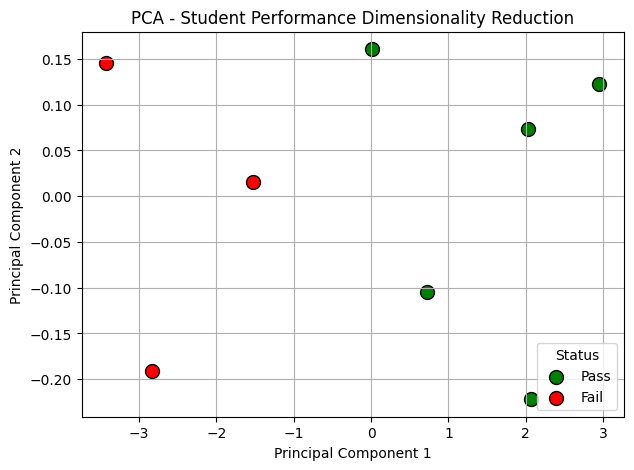

In [3]:
import io
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# -----------------------------
# Embedded Dataset
# -----------------------------
csv_data = """Math,Science,English,Computer,Attendance,Result
85,90,88,92,95,Pass
78,80,82,85,90,Pass
65,70,68,72,80,Fail
92,95,94,96,98,Pass
60,62,58,65,75,Fail
75,78,80,79,85,Pass
88,86,90,91,96,Pass
55,60,58,62,70,Fail"""

# Read dataset directly from the string variables
df = pd.read_csv(io.StringIO(csv_data))

print("Original Dataset:")
print(df)

# -----------------------------
# Feature Selection
# -----------------------------
X = df[["Math", "Science", "English", "Computer", "Attendance"]]
y = df["Result"]  # Extracted for color-coding the plot below

# -----------------------------
# Feature Scaling
# -----------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -----------------------------
# Apply PCA
# -----------------------------
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Create DataFrame for Principal Components
pca_df = pd.DataFrame(
    X_pca, columns=["Principal Component 1", "Principal Component 2"]
)

print("\nReduced Dataset:")
print(pca_df)

# Explained Variance
print("\nExplained Variance Ratio:")
print(pca.explained_variance_ratio_)

# -----------------------------
# Visualization (Updated to color-code Pass vs Fail)
# -----------------------------
plt.figure(figsize=(7, 5))

# Color-coding points by their "Result" to make the visualization meaningful
colors = {"Pass": "green", "Fail": "red"}
for result_type in y.unique():
    mask = y == result_type
    plt.scatter(
        pca_df.loc[mask, "Principal Component 1"],
        pca_df.loc[mask, "Principal Component 2"],
        c=colors[result_type],
        label=result_type,
        s=100,
        edgecolors="k",
    )

plt.title("PCA - Student Performance Dimensionality Reduction")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Status")
plt.grid(True)
plt.show()

**Result**

Feature engineering techniques were successfully applied by selecting relevant features and
reducing the dimensionality of the dataset using Principal Component Analysis (PCA). The
transformed dataset retained most of the original information while reducing the number of
features from five to two principal components, making it more suitable for visualization and
machine learning.